# Component A, Question 2: Motion Planning and Pathfinding

The robot plans on the **fused occupancy grid built from Webots sensor data**
in Question 1, rather than a hand-made map. This notebook:
1. converts the semantic map into a planning grid and inflates obstacles by the robot radius
2. implements **Dijkstra** and **A\*** (Euclidean heuristic, with Manhattan as a comparison) on an 8-connected grid
3. compares them on path optimality, nodes explored and computation time, for one route and for 300 random routes
4. reduces the chosen path to waypoints for the PID controller (Questions 3 and 4)

In [1]:
import json
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from motion_planning import (BLOCKED, build_planning_grid, cell_to_world,
                             euclidean, load_map, manhattan, path_length_m,
                             search, simplify_path, time_search,
                             world_to_cell)

MAP_FILE = Path("../question1/outputs/fused_map.npz")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

ROBOT_RADIUS = 0.037          # e-puck radius (m)
START_XY = (-0.6, -0.6)       # robot's start position in the Webots world
GOAL_XY = (0.6, 0.6)          # opposite corner of the arena

## 1. Environment representation

The fused map from Question 1 has codes −1 unknown, 0 free, 1 obstacle, and
2–4 landmarks. For planning, every non-free cell is **blocked**:
- obstacles and landmarks are physical objects
- **unknown** cells are blocked because the robot has no evidence they are safe, which is a conservative choice

Obstacles are then **inflated** by the robot radius (3.7 cm) plus a 1 cm
margin. Planning in this configuration space lets the robot be treated as a
single point. Any path through free cells keeps the robot's body clear of
obstacles.

Grid: 80 x 80 cells of 2 cm; inflation = 3 cells
Free cells after inflation: 3278 (51%)
Start cell (10, 10) free: True; goal cell (70, 70) free: True


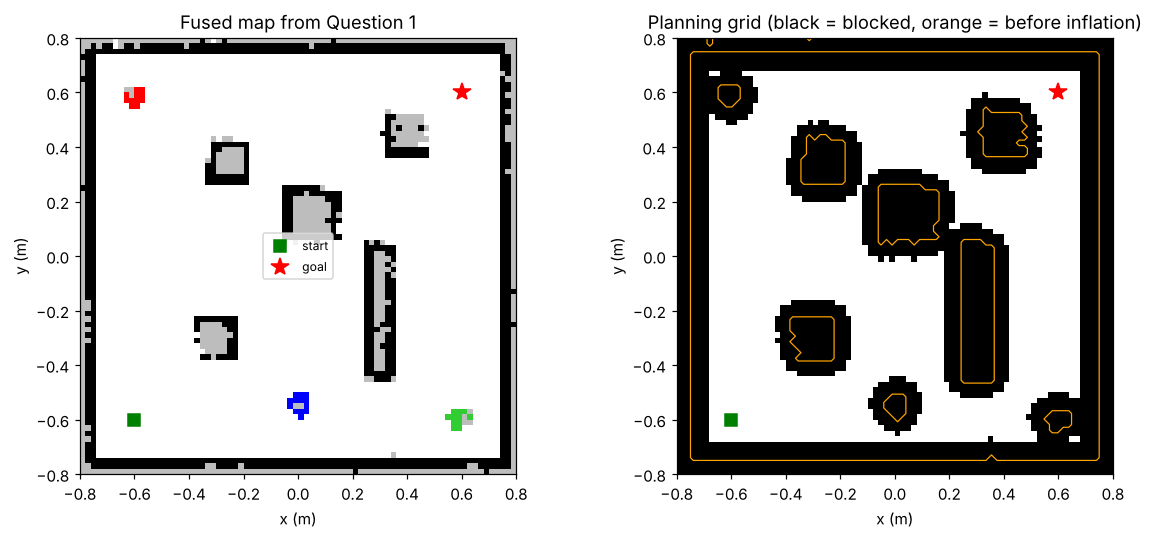

In [2]:
m = load_map(MAP_FILE)
grid, inflate_cells = build_planning_grid(m["fused"], m["resolution"],
                                          ROBOT_RADIUS)
start = world_to_cell(*START_XY, m)
goal = world_to_cell(*GOAL_XY, m)
extent = (m["x_min"], m["x_min"] + grid.shape[1] * m["resolution"],
          m["y_min"], m["y_min"] + grid.shape[0] * m["resolution"])

print(f"Grid: {grid.shape[0]} x {grid.shape[1]} cells of "
      f"{m['resolution'] * 100:.0f} cm; inflation = {inflate_cells} cells")
print(f"Free cells after inflation: {(grid == 0).sum()} "
      f"({(grid == 0).mean():.0%})")
print(f"Start cell {start} free: {grid[start] == 0}; "
      f"goal cell {goal} free: {grid[goal] == 0}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fused_cmap = ListedColormap(["#bdbdbd", "white", "black",
                             "red", "limegreen", "blue"])
axes[0].imshow(m["fused"], origin="lower", extent=extent, cmap=fused_cmap,
               vmin=-1, vmax=4, interpolation="nearest")
axes[0].set_title("Fused map from Question 1")
axes[1].imshow(grid, origin="lower", extent=extent, cmap="Greys",
               interpolation="nearest")
axes[1].contour(np.where(m["fused"] == 0, 0, 1), levels=[0.5],
                extent=extent, colors="orange", linewidths=0.8)
axes[1].set_title("Planning grid (black = blocked, orange = before inflation)")
for a in axes:
    a.plot(*START_XY, "gs", ms=8, label="start")
    a.plot(*GOAL_XY, "r*", ms=12, label="goal")
    a.set_xlabel("x (m)")
    a.set_ylabel("y (m)")
axes[0].legend(fontsize=8, loc="center")
plt.tight_layout()
plt.savefig(OUT_DIR / "q2_planning_grid.png", bbox_inches="tight")
plt.show()

## 2. Algorithms

Both algorithms use the same priority-queue search on an **8-connected** grid.
Straight moves cost 1 and diagonal moves cost √2, so the path cost equals its
true length in cells. Diagonal moves that would cut an obstacle's corner are
not allowed.

- **Dijkstra** expands cells in order of cost-so-far *g(n)*. It is guaranteed optimal, but it searches in every direction equally.
- **A\*** expands cells in order of *f(n) = g(n) + h(n)*, where *h* estimates the remaining cost to the goal.
  - **Euclidean** *h* never overestimates the true cost on this grid (it is *admissible*), so A\* stays optimal while focusing the search towards the goal.
  - **Manhattan** *h* (|Δrow| + |Δcol|) can *overestimate* when diagonal moves are allowed. That makes A\* faster, but it can return a longer path. It is included to show this trade-off.

In [3]:
algorithms = {"Dijkstra": None,
              "A* (Euclidean)": euclidean,
              "A* (Manhattan)": manhattan}

results = {name: search(grid, start, goal, h)
           for name, h in algorithms.items()}
optimal = results["Dijkstra"]["cost"]

rows = []
for name, h in algorithms.items():
    r = results[name]
    rows.append({
        "Algorithm": name,
        "Path length (m)": round(path_length_m(r["path"], m), 3),
        "Path cost / optimal": round(r["cost"] / optimal, 4),
        "Nodes expanded": r["nodes_expanded"],
        "Nodes vs Dijkstra": f"{r['nodes_expanded'] / results['Dijkstra']['nodes_expanded']:.0%}",
        "Mean time (ms, 20 runs)": round(time_search(grid, start, goal, h), 2),
    })
single = pd.DataFrame(rows)
single

,Algorithm,Path length (m),Path cost / optimal,Nodes expanded,Nodes vs Dijkstra,"Mean time (ms, 20 runs)"
0,Dijkstra,2.201,1.0,3235,100%,20.47
1,A* (Euclidean),2.201,1.0,1964,61%,15.56
2,A* (Manhattan),2.201,1.0,752,23%,6.00


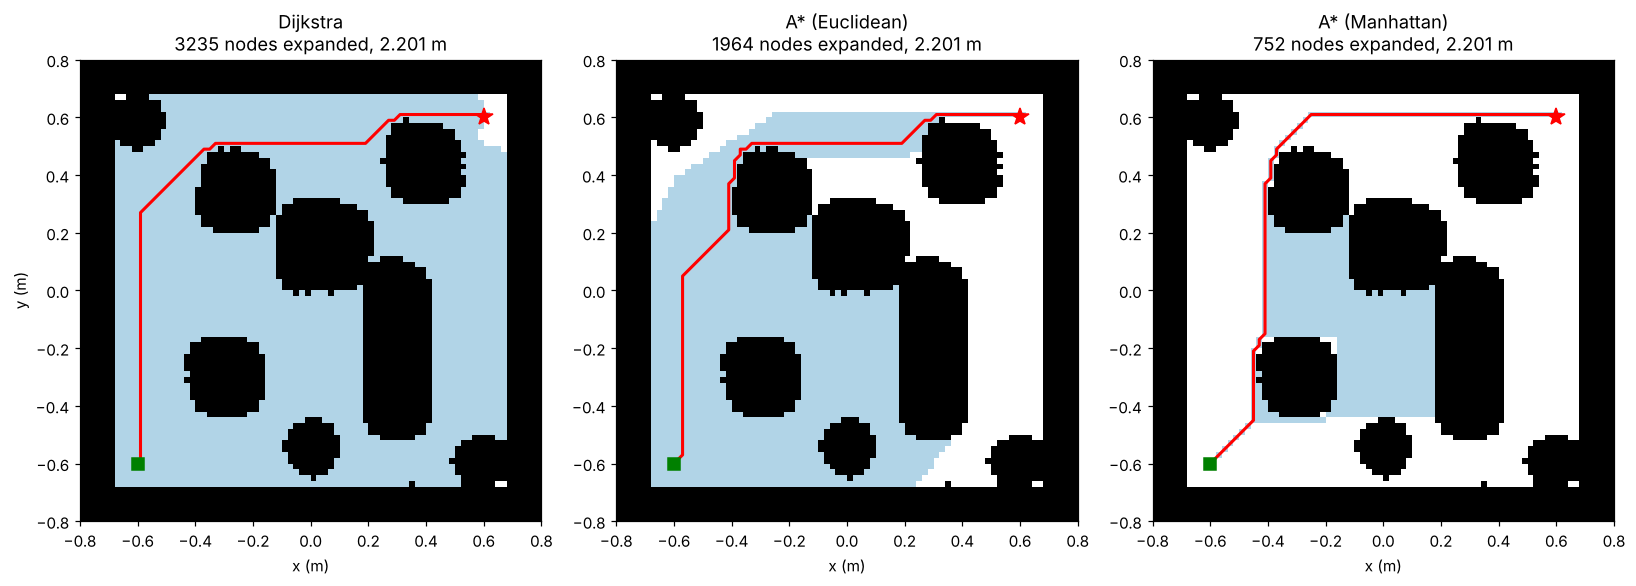

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, r) in zip(axes, results.items()):
    explored = np.zeros(grid.shape)
    for cell in r["expanded"]:
        explored[cell] = 1
    ax.imshow(grid, origin="lower", extent=extent, cmap="Greys",
              interpolation="nearest")
    ax.imshow(np.ma.masked_where(explored == 0, explored), origin="lower",
              extent=extent, cmap=ListedColormap(["#9ecae1"]), alpha=0.8,
              interpolation="nearest")
    pts = np.array([cell_to_world(*c, m) for c in r["path"]])
    ax.plot(pts[:, 0], pts[:, 1], "r-", lw=2)
    ax.plot(*START_XY, "gs", ms=8)
    ax.plot(*GOAL_XY, "r*", ms=12)
    ax.set_title(f"{name}\n{r['nodes_expanded']} nodes expanded, "
                 f"{path_length_m(r['path'], m):.3f} m")
    ax.set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.tight_layout()
plt.savefig(OUT_DIR / "q2_search_comparison.png", bbox_inches="tight")
plt.show()

**Interpretation.** The blue cells are the nodes each algorithm expanded.
Dijkstra spreads out from the start in all directions until it reaches the
goal, so it explores most of the reachable arena. A\* with the Euclidean
heuristic finds a path of **exactly the same length** while expanding far
fewer cells, because the heuristic pulls the search towards the goal. A\*
with the Manhattan heuristic is more aggressive still. Whether it stays
optimal depends on the route, which the benchmark below tests over many
start/goal pairs.

Several different paths can share the optimal length on a grid (ties), so the
algorithms may draw different routes with identical cost.

## 3. Benchmark over 300 random routes

A single route can be unrepresentative, so the three algorithms are compared
on 300 random start/goal pairs drawn from the free space. The pairs are at least
0.5 m apart, and a fixed seed makes the benchmark reproducible.

In [5]:
rng = random.Random(42)
free_cells = list(zip(*np.where(grid == 0)))
pairs = []
while len(pairs) < 300:
    a, b = rng.sample(free_cells, 2)
    if math.dist(cell_to_world(*a, m), cell_to_world(*b, m)) < 0.5:
        continue
    if search(grid, a, b, euclidean)["path"]:          # reachable only
        pairs.append((a, b))

records = []
for a, b in pairs:
    base = search(grid, a, b, None)
    for name, h in algorithms.items():
        r = base if h is None else search(grid, a, b, h)
        records.append({"Algorithm": name,
                        "Cost ratio": r["cost"] / base["cost"],
                        "Nodes": r["nodes_expanded"],
                        "Node ratio": r["nodes_expanded"] / base["nodes_expanded"],
                        "Time (ms)": time_search(grid, a, b, h, runs=3)})
bench = pd.DataFrame(records)

summary = bench.groupby("Algorithm", sort=False).agg(
    mean_nodes=("Nodes", "mean"),
    nodes_vs_dijkstra=("Node ratio", "mean"),
    mean_time_ms=("Time (ms)", "mean"),
    optimal_paths=("Cost ratio", lambda s: f"{(s < 1 + 1e-9).sum()}/{len(s)}"),
    worst_cost_ratio=("Cost ratio", "max"),
).round(3)
summary

,mean_nodes,nodes_vs_dijkstra,mean_time_ms,optimal_paths,worst_cost_ratio
Algorithm,,,,,
Dijkstra,2074.153,1.000,23.239,300/300,1.000
A* (Euclidean),619.417,0.270,7.864,300/300,1.000
A* (Manhattan),337.700,0.141,6.083,284/300,1.115


In [6]:
manh = bench[bench.Algorithm == "A* (Manhattan)"]
longer = manh[manh["Cost ratio"] > 1 + 1e-9]
print(f"Manhattan A* returned a longer-than-optimal path on "
      f"{len(longer)} of {len(manh)} routes ({len(longer) / len(manh):.1%}); "
      f"when it did, the path was on average "
      f"{(longer['Cost ratio'].mean() - 1):.1%} longer "
      f"(worst {(longer['Cost ratio'].max() - 1):.1%}).")

Manhattan A* returned a longer-than-optimal path on 16 of 300 routes (5.3%); when it did, the path was on average 5.5% longer (worst 11.5%).


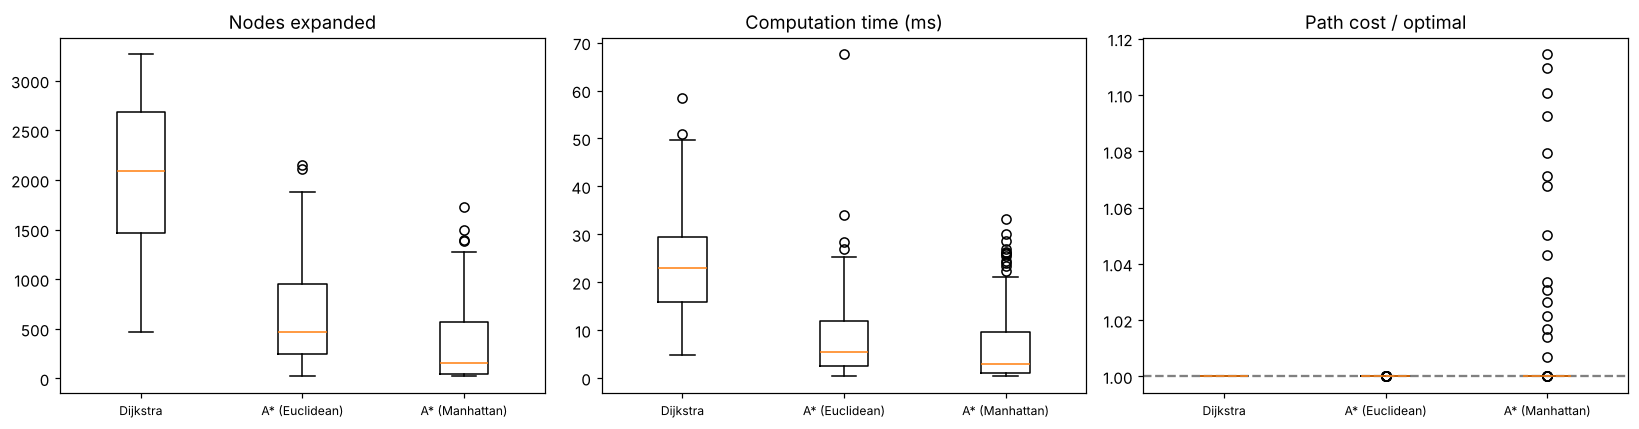

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = list(algorithms)
for ax, col, title in zip(axes, ["Nodes", "Time (ms)", "Cost ratio"],
                          ["Nodes expanded", "Computation time (ms)",
                           "Path cost / optimal"]):
    ax.boxplot([bench.loc[bench.Algorithm == a, col] for a in order])
    ax.set_xticks(range(1, len(order) + 1))   # works on any matplotlib
    ax.set_xticklabels(order)
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=8)
axes[2].axhline(1.0, ls="--", c="grey")
plt.tight_layout()
plt.savefig(OUT_DIR / "q2_benchmark.png", bbox_inches="tight")
plt.show()

**Interpretation.**
- **Optimality.** Dijkstra and A\* (Euclidean) returned optimal paths on every route, as theory predicts: Dijkstra is exhaustive, and an admissible heuristic preserves optimality.
- **Efficiency.** A\* (Euclidean) expanded substantially fewer nodes and ran faster on average. Its advantage is largest on long, open routes and smallest when walls force the path away from the straight line to the goal, because then the heuristic misleads the search.
- **Manhattan heuristic.** It expanded the fewest nodes, but it overestimates diagonal distances, so it is not admissible on an 8-connected grid. On most routes it still found an optimal path, but on a small fraction it returned a noticeably longer one (quantified above). The speed comes at the cost of the optimality guarantee, and a single test route would never have revealed this.
- **Choice.** **A\* with the Euclidean heuristic** is used for the robot. It gives optimal paths at a fraction of Dijkstra's search effort. A slightly longer path would be an acceptable trade only if planning time were critical, for example when replanning many times per second.

## 4. Waypoints for the controller

The optimal cell path contains many short steps, which would make a PID
controller turn constantly. **Line-of-sight shortcutting** keeps only the cells
where the direction must change, provided each straight segment between
waypoints stays inside free (inflated) space. The result is a short list of
waypoints for the PID path follower in Questions 3 and 4.

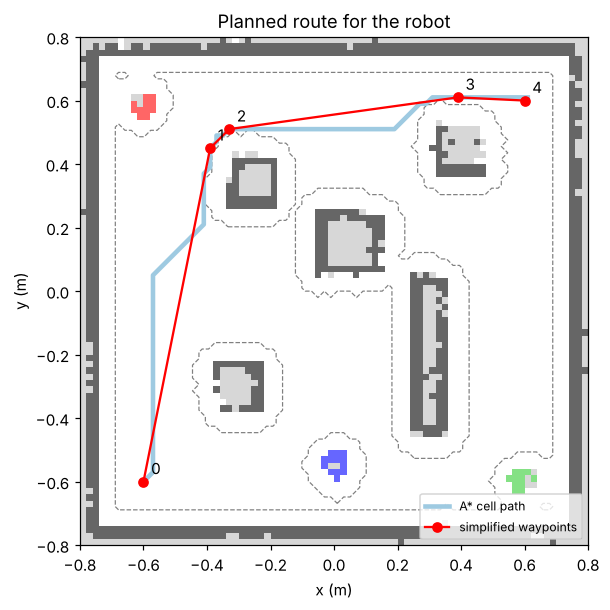

,x (m),y (m)
0,-0.60,-0.60
1,-0.39,0.45
2,-0.33,0.51
3,0.39,0.61
4,0.60,0.60


In [8]:
best = results["A* (Euclidean)"]
waypoint_cells = simplify_path(grid, best["path"])
waypoints = [cell_to_world(*c, m) for c in waypoint_cells]
waypoints[0], waypoints[-1] = START_XY, GOAL_XY     # exact endpoints

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(m["fused"], origin="lower", extent=extent, cmap=fused_cmap,
          vmin=-1, vmax=4, interpolation="nearest", alpha=0.6)
ax.contour(grid, levels=[0.5], extent=extent, colors="grey",
           linewidths=0.8, linestyles="--")
pts = np.array([cell_to_world(*c, m) for c in best["path"]])
ax.plot(pts[:, 0], pts[:, 1], "-", c="#9ecae1", lw=3, label="A* cell path")
wp = np.array(waypoints)
ax.plot(wp[:, 0], wp[:, 1], "ro-", lw=1.5, label="simplified waypoints")
for k, (x, y) in enumerate(waypoints):
    ax.annotate(str(k), (x, y), textcoords="offset points", xytext=(5, 5))
ax.set_title("Planned route for the robot")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(fontsize=8, loc="lower right")
plt.savefig(OUT_DIR / "q2_waypoints.png", bbox_inches="tight")
plt.show()

plan = {"start": START_XY, "goal": GOAL_XY,
        "waypoints": [[round(x, 4), round(y, 4)] for x, y in waypoints],
        "cell_path_length_m": round(path_length_m(best["path"], m), 4),
        "waypoint_path_length_m": round(sum(math.dist(waypoints[i],
                                                      waypoints[i + 1])
                                            for i in range(len(waypoints) - 1)), 4),
        "robot_radius_m": ROBOT_RADIUS}
with open(OUT_DIR / "planned_path.json", "w") as f:
    json.dump(plan, f, indent=2)
pd.DataFrame(plan["waypoints"], columns=["x (m)", "y (m)"])

In [9]:
print(f"Cell path: {len(best['path'])} cells, "
      f"{plan['cell_path_length_m']} m")
print(f"Waypoint path: {len(waypoints)} waypoints, "
      f"{plan['waypoint_path_length_m']} m")
print("Saved", OUT_DIR / "planned_path.json")

Cell path: 104 cells, 2.2008 m
Waypoint path: 5 waypoints, 2.0928 m
Saved outputs/planned_path.json


Shortcutting makes the route **shorter** than the grid-optimal path, because
grid paths are restricted to 45° angles while straight segments are not. The
grid "optimum" is only optimal among paths that move between cell centres.

**Limitations**
- **Grid resolution.** 2 cm cells trade accuracy for search time. A finer grid gives smoother paths but more nodes.
- **Static map.** The plan assumes the map from Question 1 is complete and unchanging. Moving people or objects would require replanning, where A\*'s speed matters most.
- **Conservative unknown space.** Treating unknown cells as blocked is safe, but it could make a goal unreachable in a poorly explored map. An exploration step would be needed in that case.